## EDA ngày 12–13/11/2026

Nguồn: results/2026-11-12_194905_617600 và results/2026-11-13_113519_605332, cập nhật từ GitHub commit 820f0bd. Hai lần chạy là hai bộ kết quả, không mặc định là hai bộ dữ liệu độc lập. Kiểm tra chất lượng trên toàn bộ nguồn; khám phá quan hệ đặc trưng chỉ trên train theo split đã lưu. Phần validation chỉ phân tích kết quả đã có. Không huấn luyện lại, không mở mô hình joblib, không đánh giá test.

In [1]:
from pathlib import Path
import hashlib, io, json, platform, sys
from datetime import datetime, timezone, timedelta
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import sklearn
from IPython.display import Image
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, accuracy_score, precision_recall_curve)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "ai4i").is_dir() and (p / "data/ai4i2020.csv").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from ai4i.config import NUM, FE
from ai4i.data import augment

RUNS = ["2026-11-12_194905_617600", "2026-11-13_113519_605332"]
MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]
TARGET = "Machine failure"
source = ROOT / "data/ai4i2020.csv"
df = pd.read_csv(source)
data_hash = hashlib.sha256(source.read_bytes()).hexdigest()
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

def table(frame):
    display(frame)

def figure(fig):
    fig.tight_layout()
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=145, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

metadata, splits, logs, predictions = {}, {}, {}, {}
provenance = []
for name in RUNS:
    folder = ROOT / "results" / name
    meta = json.loads((folder / "metadata.json").read_text(encoding="utf-8"))
    split = pd.read_csv(folder / "split_indices.csv")
    log = pd.read_csv(folder / "experiment_log.csv")
    assert meta["data_sha256"] == data_hash, f"Source hash mismatch: {name}"
    assert not split["row_index"].duplicated().any()
    assert set(split["row_index"]) == set(df.index)
    assert set(split["split"]) == {"train", "validation", "test"}
    assert not log[["run", "model"]].duplicated().any()
    assert len(log) == 17 and log["status"].eq("success").all()
    assert log["evaluation_set"].eq("validation").all()
    assert not meta["test_evaluated"]
    for label in ["train", "validation", "test"]:
        assert split["split"].eq(label).sum() == meta["n_" + label]
    metadata[name], splits[name], logs[name] = meta, split, log
    provenance.append({"result_set": name, "started_at": meta["started_at"],
        "source_hash_matches": True, "python_training": meta["python"],
        "seed": meta["seed"], "models": len(log), "test_evaluated": meta["test_evaluated"]})
same_split = splits[RUNS[0]].sort_values("row_index").reset_index(drop=True).equals(
    splits[RUNS[1]].sort_values("row_index").reset_index(drop=True))
assert same_split, "Use separate train EDA when split manifests differ"
train_ids = splits[RUNS[-1]].query("split == 'train'")["row_index"]
validation_ids = splits[RUNS[-1]].query("split == 'validation'")["row_index"]
train = df.loc[train_ids].copy()
table(pd.DataFrame(provenance))
print("Data SHA256:", data_hash)
print("Same complete split manifests:", same_split)


result_set,started_at,source_hash_matches,python_training,seed,models,test_evaluated
2026-11-12_194905_617600,2026-11-12T19:49:05+07:00,True,3.14.2,42,17,False
2026-11-13_113519_605332,2026-11-13T11:35:19+07:00,True,3.14.2,42,17,False


Data SHA256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
Same complete split manifests: True


## 1. Chất lượng nguồn và vai trò từng cột

UDI và Product ID dùng để truy vết; Type và 5 biến vận hành là đầu vào. TWF/HDF/PWF/OSF/RNF là các cờ loại lỗi, chỉ dùng kiểm tra nhãn; đưa chúng vào X có nguy cơ rò rỉ nhãn. Kiểm tra chất lượng toàn nguồn không dùng để chọn đặc trưng hoặc điều chỉnh mô hình.

In [2]:
quality = pd.DataFrame([{"scope": label, "rows": len(part), "columns": len(part.columns),
    "missing_cells": int(part.isna().sum().sum()), "duplicate_full_rows": int(part.duplicated().sum()),
    "duplicate_UDI": int(part["UDI"].duplicated().sum()),
    "nonfinite_numeric": int((~np.isfinite(part[NUM])).sum().sum())}
    for label, part in [("source", df), ("train", train)]])
table(quality)
roles = pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values,
    "missing": df.isna().sum().values, "unique": df.nunique().values})
roles["role"] = roles["column"].map(lambda c: "target" if c == TARGET else
    "input" if c in ["Type", *NUM] else "failure flag (exclude from X)" if c in MODES else "identifier (exclude from X)")
table(roles)
mismatch = df[TARGET].ne(df[MODES].max(axis=1))
split_lookup = splits[RUNS[-1]].set_index("row_index")["split"]
issues = df.loc[mismatch, ["UDI", TARGET, *MODES]].copy()
issues["split"] = split_lookup.reindex(issues.index)
table(issues)
print(f"Label / OR(flags) mismatches: {mismatch.sum()}; retain source labels.")


scope,rows,columns,missing_cells,duplicate_full_rows,duplicate_UDI,nonfinite_numeric
source,10000,14,0,0,0,0
train,7000,14,0,0,0,0


column,dtype,missing,unique,role
UDI,int64,0,10000,identifier (exclude from X)
Product ID,str,0,10000,identifier (exclude from X)
Type,str,0,3,input
Air temperature [K],float64,0,93,input
Process temperature [K],float64,0,82,input
Rotational speed [rpm],int64,0,941,input
Torque [Nm],float64,0,577,input
Tool wear [min],int64,0,246,input
Machine failure,int64,0,2,target
TWF,int64,0,2,failure flag (exclude from X)


UDI,Machine failure,TWF,HDF,PWF,OSF,RNF,split
1222,0,0,0,0,0,1,train
1303,0,0,0,0,0,1,train
1438,1,0,0,0,0,0,train
1749,0,0,0,0,0,1,train
2073,0,0,0,0,0,1,train
2560,0,0,0,0,0,1,test
2750,1,0,0,0,0,0,train
3066,0,0,0,0,0,1,validation
3453,0,0,0,0,0,1,train
4045,1,0,0,0,0,0,train


Label / OR(flags) mismatches: 27; retain source labels.


## 2. Phép chia và mất cân bằng nhãn

Hai manifest được đối chiếu toàn bộ row_index và split. Bảng dưới chỉ mô tả số lượng và tỷ lệ nhãn của từng tập; phân tích phân bố đặc trưng ở các mục sau chỉ dùng train. Accuracy luôn đoán bình thường được trình bày để thấy vì sao cần precision, recall, F1 và PR.

split,samples,failures,failure_rate
test,1500,51,0.0340
train,7000,237,0.0339
validation,1500,51,0.0340


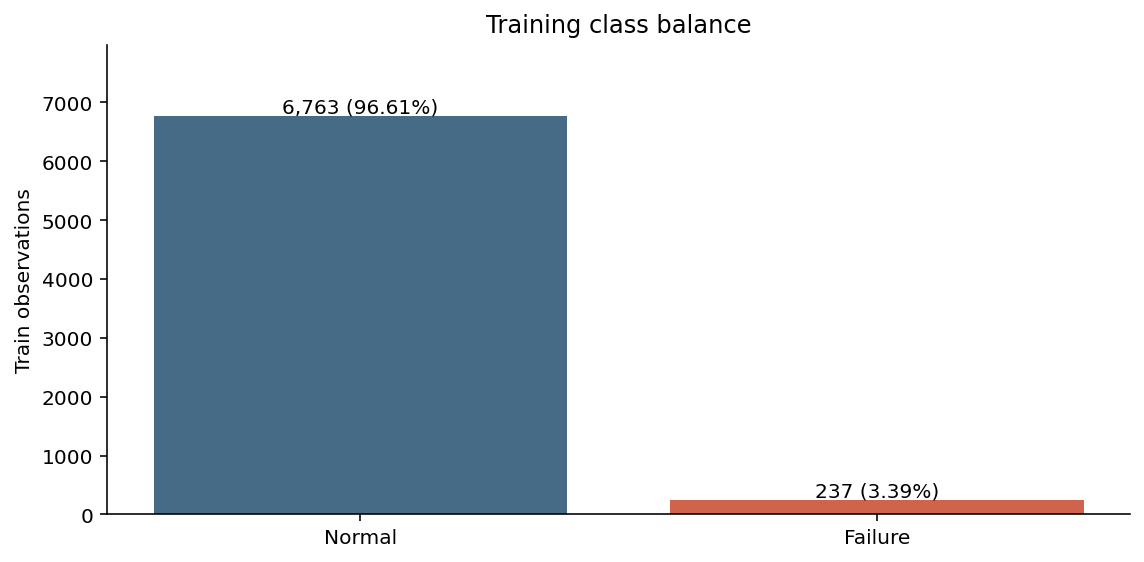

Always-normal train accuracy: 96.61%; failure recall/F1 = 0.


In [3]:
split_summary = splits[RUNS[-1]].merge(df[[TARGET]], left_on="row_index", right_index=True)
split_summary = split_summary.groupby("split")[TARGET].agg(samples="size", failures="sum", failure_rate="mean").reset_index()
table(split_summary)
counts = train[TARGET].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(["Normal", "Failure"], counts, color=["#456b87", "#cf634b"])
for i, n in enumerate(counts):
    ax.text(i, n, f"{n:,} ({n / len(train):.2%})", ha="center", va="bottom")
ax.set(ylabel="Train observations", title="Training class balance", ylim=(0, counts.max() * 1.18))
figure(fig)
print(f"Always-normal train accuracy: {counts[0] / counts.sum():.2%}; failure recall/F1 = 0.")


## 3. Phân bố đầu vào và điểm cực trị trên train

Histogram và boxplot thể hiện miền giá trị, độ lệch và sự chồng lấp hai lớp. IQR là quy tắc gắn cờ để kiểm tra, không phải bằng chứng giá trị sai; giữ nguyên các điểm cực trị.

feature,count,mean,std,min,25%,50%,75%,max
Air temperature [K],7000.0000,300.0144,2.0027,295.3000,298.3000,300.1000,301.5000,304.5000
Process temperature [K],7000.0000,310.0066,1.4816,305.7000,308.8000,310.1000,311.1000,313.8000
Rotational speed [rpm],7000.0000,1539.2374,180.2375,1168.0000,1423.0000,1504.0000,1614.0000,2886.0000
Torque [Nm],7000.0000,40.0013,10.0060,3.8000,33.2000,40.1000,46.8000,76.6000
Tool wear [min],7000.0000,107.6236,63.8639,0.0000,52.0000,107.0000,163.0000,253.0000


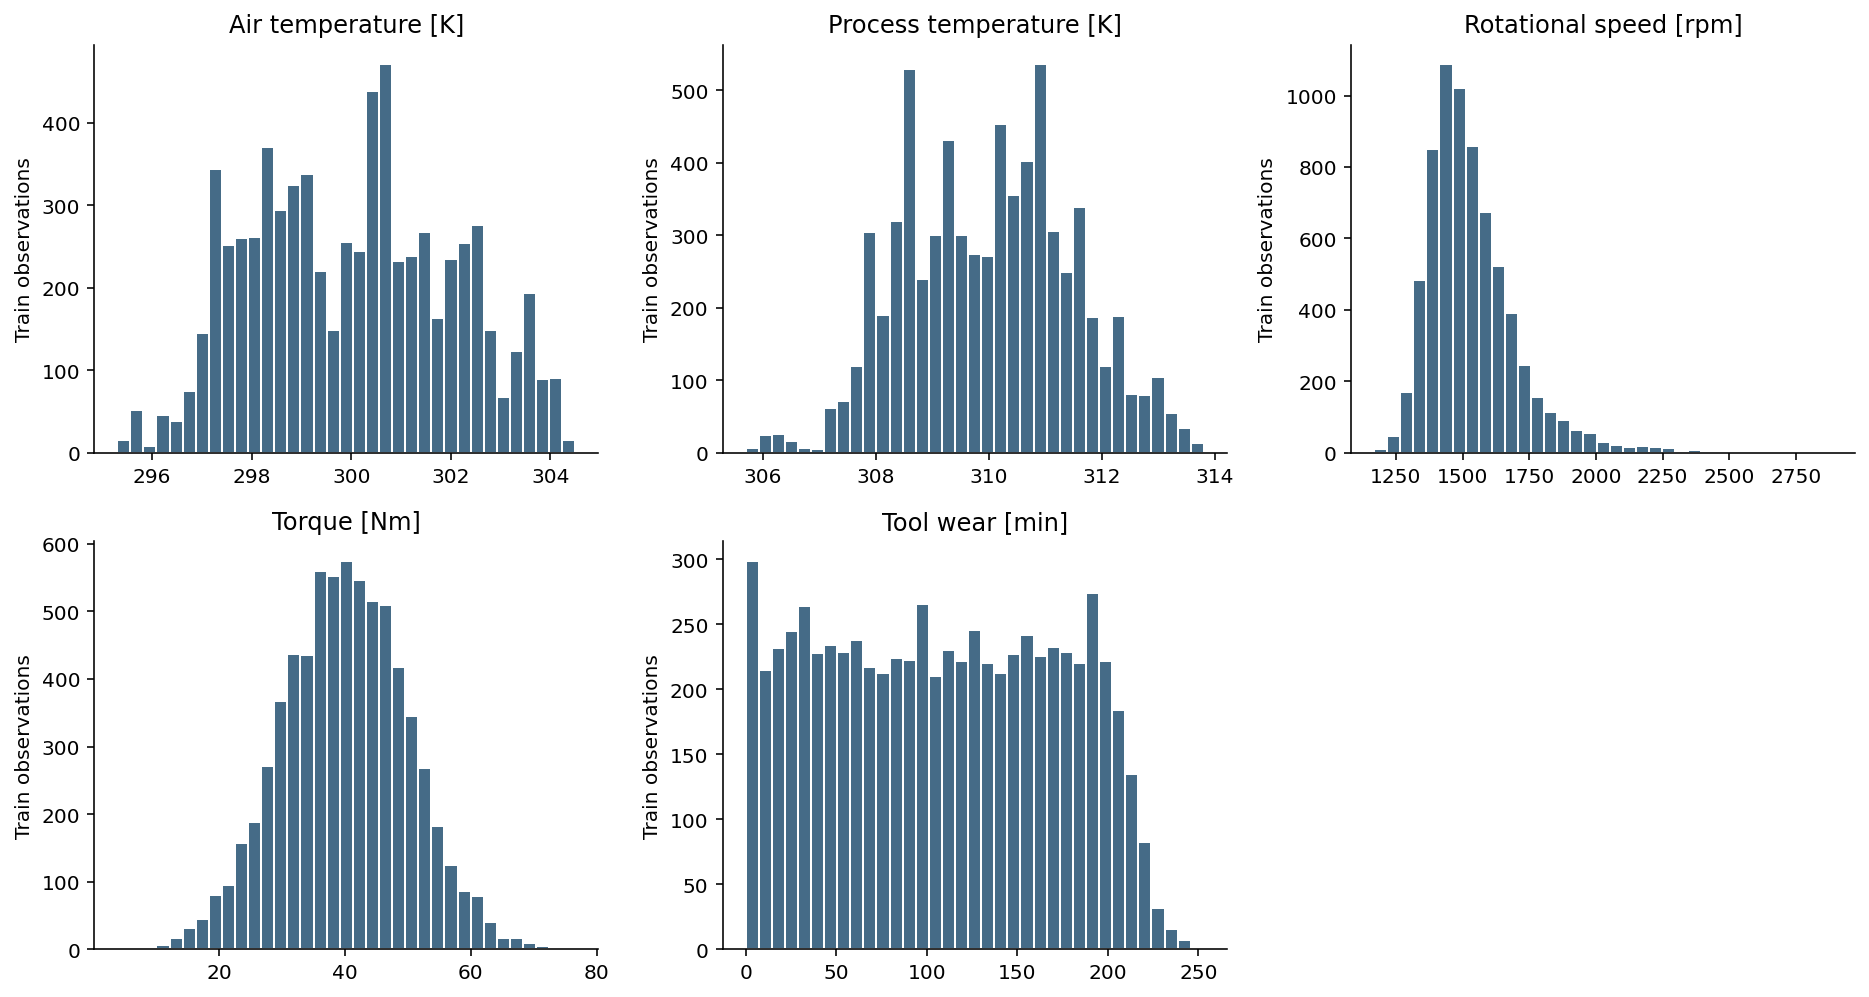

feature,lower_fence,upper_fence,flagged_count,flagged_failure_count
Air temperature [K],293.5000,306.3000,0,0
Process temperature [K],305.3500,314.5500,0,0
Rotational speed [rpm],1136.5000,1900.5000,284,27
Torque [Nm],12.8000,67.2000,51,47
Tool wear [min],-114.5000,329.5000,0,0


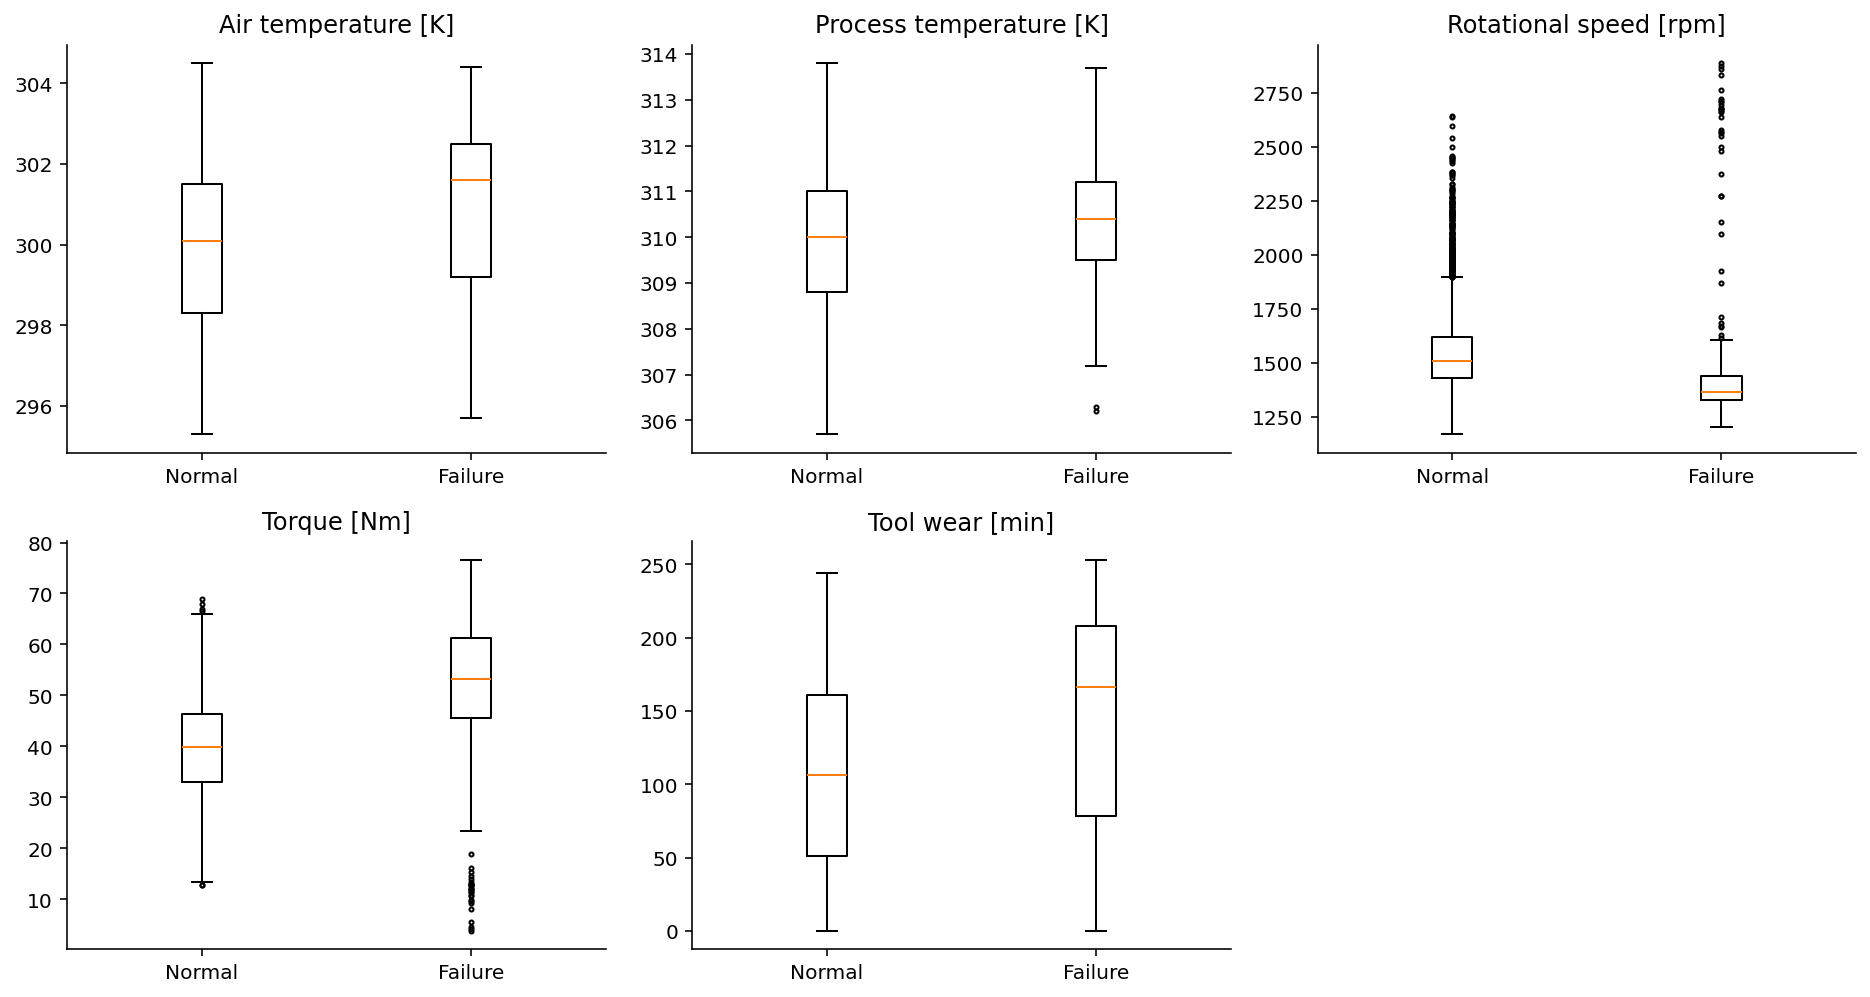

In [4]:
table(train[NUM].describe().T.rename_axis("feature").reset_index())
iqr_rows = []
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, ax in zip(NUM, axes.flat):
    ax.hist(train[col], bins=35, color="#456b87", edgecolor="white")
    ax.set(title=col, ylabel="Train observations")
    q1, q3 = train[col].quantile([.25, .75]); spread = q3 - q1
    flagged = (train[col] < q1 - 1.5 * spread) | (train[col] > q3 + 1.5 * spread)
    iqr_rows.append({"feature": col, "lower_fence": q1 - 1.5 * spread,
        "upper_fence": q3 + 1.5 * spread, "flagged_count": int(flagged.sum()),
        "flagged_failure_count": int(train.loc[flagged, TARGET].sum())})
axes.flat[-1].axis("off")
figure(fig)
table(pd.DataFrame(iqr_rows))
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for col, ax in zip(NUM, axes.flat):
    ax.boxplot([train.loc[train[TARGET].eq(c), col] for c in [0, 1]],
               tick_labels=["Normal", "Failure"], showfliers=True, flierprops={"markersize": 2})
    ax.set(title=col)
axes.flat[-1].axis("off")
figure(fig)


## 4. Tỷ lệ lỗi theo Type và các cờ loại lỗi trên train

Tỷ lệ được đọc cùng số quan sát và khoảng Wilson 95%, đặc biệt với nhóm ít mẫu. Các cờ lỗi có thể chồng lấp, nên tổng cờ không phải số máy lỗi. Đây là liên hệ mô tả, không phải nhân quả.

Type,samples,failures,failure_rate,wilson_low,wilson_high
H,705,14,0.0199,0.0119,0.0331
L,4217,175,0.0415,0.0359,0.0479
M,2078,48,0.0231,0.0175,0.0305


mode,flag_count
TWF,33
HDF,73
PWF,72
OSF,71
RNF,13


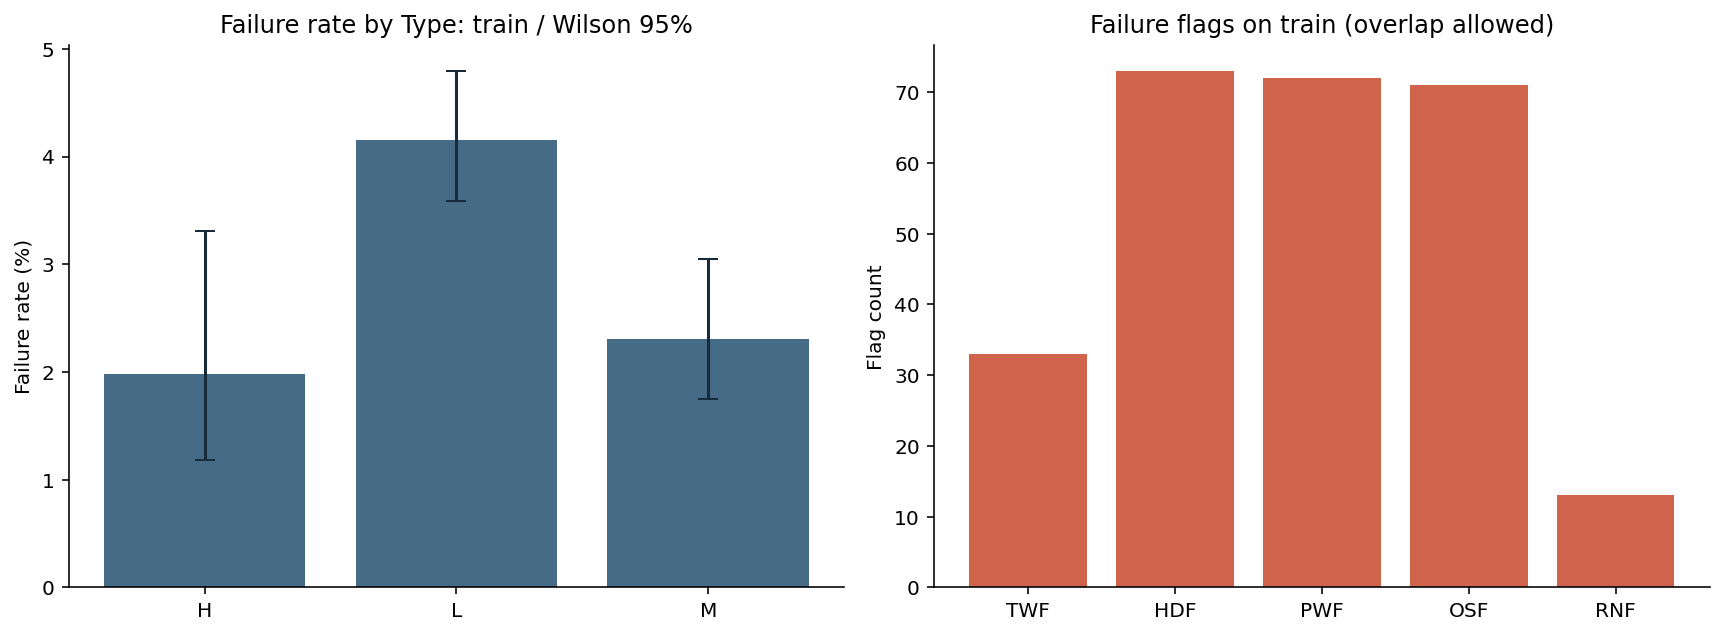

In [5]:
types = train.groupby("Type")[TARGET].agg(samples="size", failures="sum", failure_rate="mean").reset_index()
z = 1.959963984540054
n, p = types["samples"], types["failure_rate"]
center = (p + z*z/(2*n)) / (1 + z*z/n)
half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
types["wilson_low"], types["wilson_high"] = center-half, center+half
table(types)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(types["Type"], p*100, color="#456b87")
axes[0].errorbar(types["Type"], p*100, yerr=[(p-types.wilson_low)*100,
    (types.wilson_high-p)*100], fmt="none", color="#172b3a", capsize=5)
axes[0].set(title="Failure rate by Type: train / Wilson 95%", ylabel="Failure rate (%)")
mode_counts = train[MODES].sum().rename_axis("mode").reset_index(name="flag_count")
table(mode_counts)
axes[1].bar(mode_counts["mode"], mode_counts["flag_count"], color="#cf634b")
axes[1].set(title="Failure flags on train (overlap allowed)", ylabel="Flag count")
figure(fig)


## 5. Tương quan, tương tác và đặc trưng E01/E03 trên train

Ma trận chỉ gồm 5 biến số đầu vào. Scatter thể hiện tốc độ–mô-men và mòn–mô-men. Ba đặc trưng đã được dùng trong E01/E03 là chênh lệch nhiệt độ, công suất ước tính và mòn × mô-men; các biểu đồ chỉ giải thích những thí nghiệm đã có, không chứng minh nguyên nhân.

feature,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Air temperature [K],1.0000,0.8775,0.0241,-0.0163,0.0125
Process temperature [K],0.8775,1.0000,0.0183,-0.0157,0.0142
Rotational speed [rpm],0.0241,0.0183,1.0000,-0.8738,-0.0023
Torque [Nm],-0.0163,-0.0157,-0.8738,1.0000,-0.0044
Tool wear [min],0.0125,0.0142,-0.0023,-0.0044,1.0000


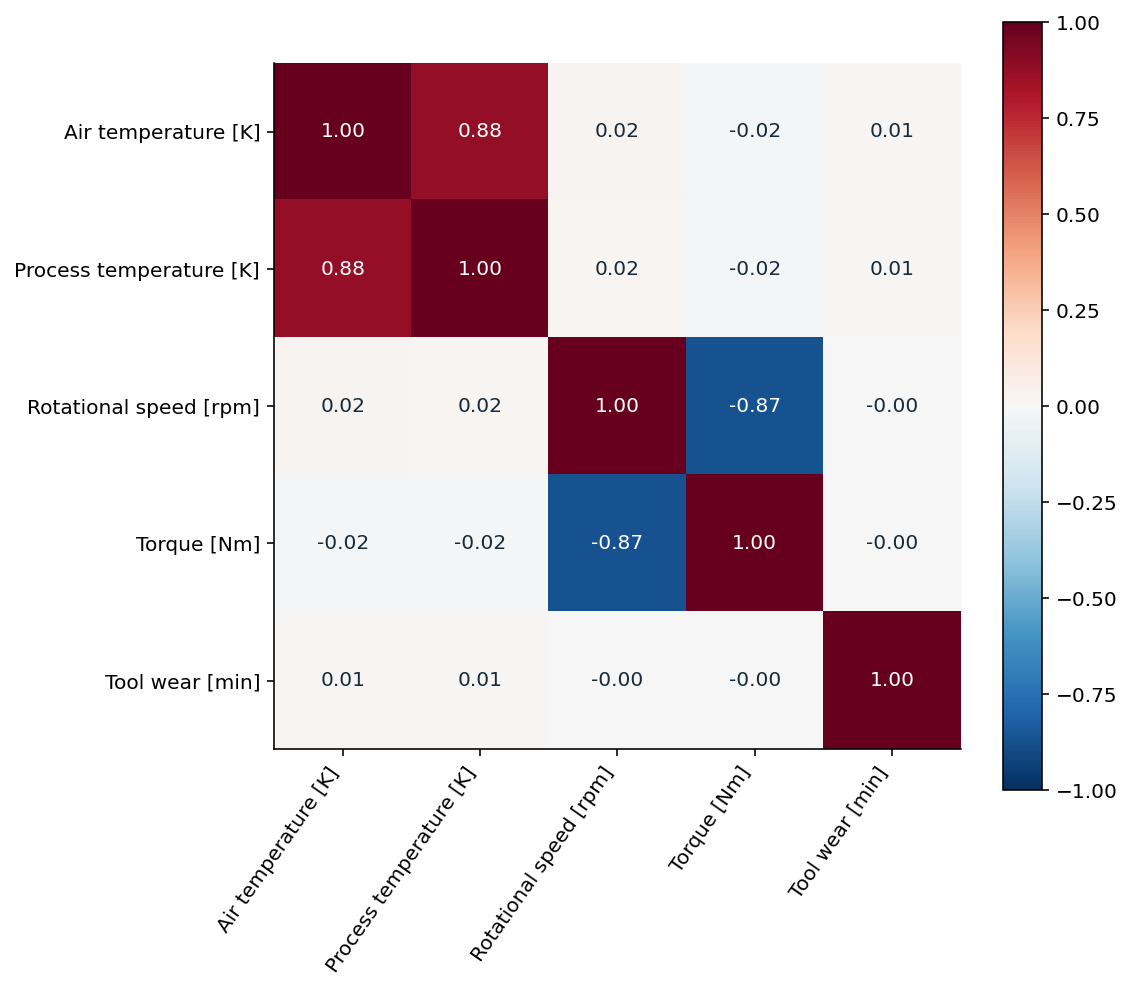

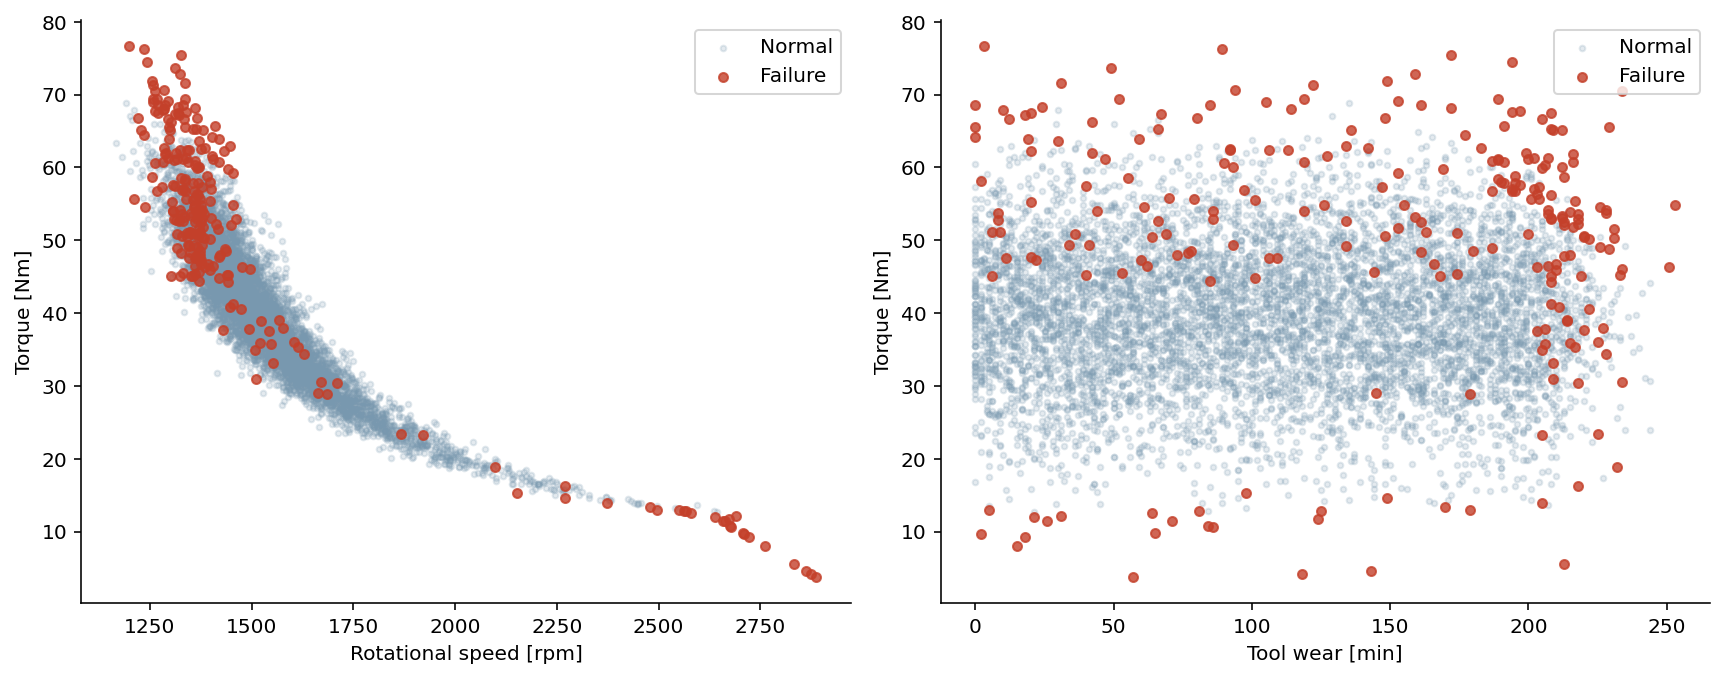

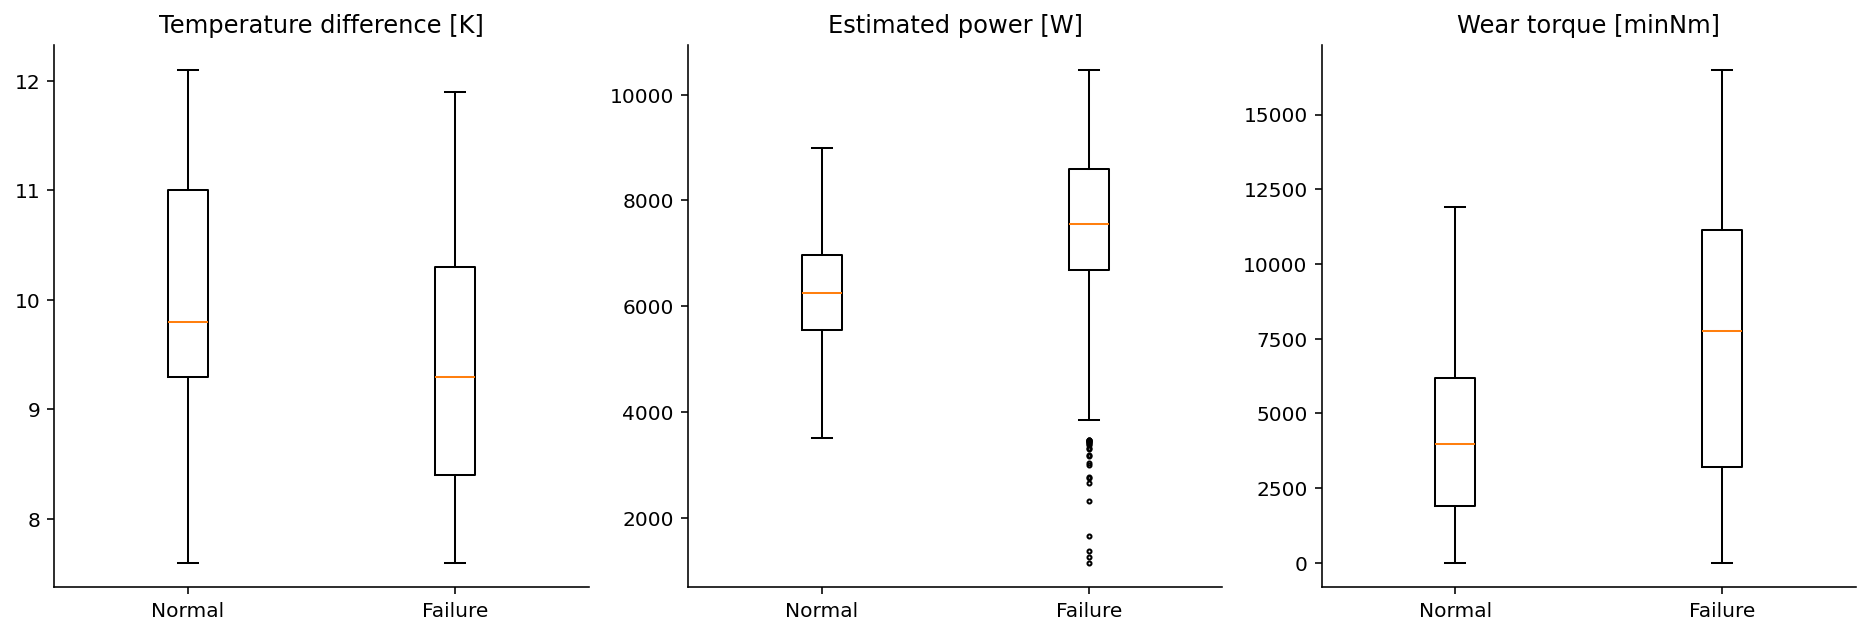

In [6]:
corr = train[NUM].corr()
table(corr.rename_axis("feature").reset_index())
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(NUM)), NUM, rotation=55, ha="right")
ax.set_yticks(range(len(NUM)), NUM)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center",
            color="white" if abs(corr.iloc[i,j]) > .65 else "#172b3a")
fig.colorbar(im, ax=ax)
figure(fig)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, x, y in [(axes[0], NUM[2], NUM[3]), (axes[1], NUM[4], NUM[3])]:
    for label, color in [(0, "#7898af"), (1, "#c4402a")]:
        subset = train.loc[train[TARGET].eq(label)]
        ax.scatter(subset[x], subset[y], s=8 if label == 0 else 20,
            alpha=.2 if label == 0 else .8, color=color, label=["Normal", "Failure"][label])
    ax.set(xlabel=x, ylabel=y); ax.legend()
figure(fig)
engineered = augment(train[["Type", *NUM]])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for col, ax in zip(FE, axes):
    ax.boxplot([engineered.loc[train[TARGET].eq(c), col] for c in [0, 1]],
        tick_labels=["Normal", "Failure"], flierprops={"markersize": 2})
    ax.set(title=col)
figure(fig)


## 6. Kiểm chứng độc lập các CSV dự đoán của cả 34 cấu hình

Đối chiếu ID, nhãn thật với nguồn, tập validation với manifest, miền xác suất và nhãn dự đoán. Tính lại precision, recall, F1, ROC AUC, average precision, accuracy và TN/FP/FN/TP; so sánh với metrics.json, experiment_log.csv và model_comparison.csv. Đây là kiểm tra CSV, không phải nạp lại hay tái kiểm chứng các mô hình joblib.

In [7]:
checks, result_rows = [], []
for name in RUNS:
    folder = ROOT / "results" / name
    comparison = pd.read_csv(folder / "model_comparison.csv")
    assert len(comparison) == 17 and not comparison[["run", "model"]].duplicated().any()
    for _, row in logs[name].iterrows():
        key = (row["run"], row["model"])
        pred = pd.read_csv(folder / key[0] / key[1] / "validation_predictions.csv")
        assert pred["row_index"].is_unique and len(pred) == len(validation_ids)
        assert set(pred["row_index"]) == set(validation_ids)
        expected = df.loc[pred["row_index"]]
        assert np.array_equal(pred["UDI"], expected["UDI"])
        assert np.array_equal(pred["actual"], expected[TARGET])
        assert pred["actual"].isin([0, 1]).all() and pred["predicted"].isin([0, 1]).all()
        assert pred["failure_probability"].between(0, 1).all()
        outcomes = np.select([(pred.actual == 1) & (pred.predicted == 1),
            (pred.actual == 1) & (pred.predicted == 0),
            (pred.actual == 0) & (pred.predicted == 1)], ["TP", "FN", "FP"], default="TN")
        assert np.array_equal(pred["outcome"], outcomes)
        y, h, probability = pred.actual, pred.predicted, pred.failure_probability
        tn, fp, fn, tp = confusion_matrix(y, h, labels=[0, 1]).ravel()
        computed = dict(precision=precision_score(y, h, zero_division=0),
            recall=recall_score(y, h, zero_division=0), f1=f1_score(y, h, zero_division=0),
            roc_auc=roc_auc_score(y, probability), average_precision=average_precision_score(y, probability),
            accuracy=accuracy_score(y, h), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
        saved = json.loads((folder / key[0] / key[1] / "metrics.json").read_text())
        compare_row = comparison.loc[(comparison.run == key[0]) & (comparison.model == key[1])].iloc[0]
        assert saved["evaluation_set"] == "validation"
        for metric, value in computed.items():
            for target in [saved, row, compare_row]:
                if metric in target:
                    assert np.isclose(value, target[metric], rtol=0, atol=1e-12), (name, key, metric)
        predictions[(name, *key)] = pred.sort_values("row_index").reset_index(drop=True)
        checks.append({"result_set": name, "run": key[0], "model": key[1],
            "validation_rows": len(pred), "csv_metrics_match": True})
        result_rows.append({"result_set": name, "run": key[0], "model": key[1], **computed,
            "train_f1": row.train_f1, "f1_gap": row.train_f1 - computed["f1"],
            "fit_seconds": row.fit_seconds})
metrics = pd.DataFrame(result_rows)
table(pd.DataFrame(checks))
table(metrics)


result_set,run,model,validation_rows,csv_metrics_match
2026-11-12_194905_617600,E00,Dummy,1500,True
2026-11-12_194905_617600,E00,LogisticRegression,1500,True
2026-11-12_194905_617600,E00,DecisionTree,1500,True
2026-11-12_194905_617600,E00,RandomForest,1500,True
2026-11-12_194905_617600,E00,GradientBoosting,1500,True
2026-11-12_194905_617600,E01,LogisticRegression,1500,True
2026-11-12_194905_617600,E01,DecisionTree,1500,True
2026-11-12_194905_617600,E01,RandomForest,1500,True
2026-11-12_194905_617600,E01,GradientBoosting,1500,True
2026-11-12_194905_617600,E02,LogisticRegression,1500,True


result_set,run,model,precision,recall,f1,roc_auc,average_precision,accuracy,tn,fp,fn,tp,train_f1,f1_gap,fit_seconds
2026-11-12_194905_617600,E00,Dummy,0.0000,0.0000,0.0000,0.5000,0.0340,0.9660,1449,0,51,0,0.0000,0.0000,0.0364
2026-11-12_194905_617600,E00,LogisticRegression,0.1365,0.7255,0.2298,0.8750,0.3829,0.8347,1215,234,14,37,0.2427,0.0129,0.0461
2026-11-12_194905_617600,E00,DecisionTree,0.3304,0.7255,0.4540,0.7421,0.3763,0.9407,1374,75,14,37,0.5520,0.0980,0.0483
2026-11-12_194905_617600,E00,RandomForest,0.7027,0.5098,0.5909,0.9739,0.6389,0.9760,1438,11,25,26,0.9916,0.4007,1.2842
2026-11-12_194905_617600,E00,GradientBoosting,0.8824,0.5882,0.7059,0.9772,0.8094,0.9833,1445,4,21,30,0.8779,0.1721,0.5329
2026-11-12_194905_617600,E01,LogisticRegression,0.1695,0.7843,0.2787,0.9048,0.3561,0.8620,1253,196,11,40,0.2863,0.0076,0.0577
2026-11-12_194905_617600,E01,DecisionTree,0.4404,0.9412,0.6000,0.9496,0.8002,0.9573,1388,61,3,48,0.6191,0.0191,0.0576
2026-11-12_194905_617600,E01,RandomForest,0.9268,0.7451,0.8261,0.9801,0.8721,0.9893,1446,3,13,38,0.9979,0.1718,1.7194
2026-11-12_194905_617600,E01,GradientBoosting,1.0000,0.8431,0.9149,0.9826,0.9229,0.9947,1449,0,8,43,0.9300,0.0151,0.8966
2026-11-12_194905_617600,E02,LogisticRegression,0.1370,0.7255,0.2305,0.8749,0.3848,0.8353,1216,233,14,37,0.2422,0.0117,1.4122


## 7. E00–E03: F1, precision/recall và chênh lệch train–validation

E00: gốc; E01: thêm đặc trưng; E02: tuning biến gốc; E03: thêm đặc trưng và tuning. Phân tích cả hai lần chạy, không chọn một lần có kết quả thuận lợi hơn. Chênh lệch train–validation chỉ là dấu hiệu mô tả; không tự nó chứng minh overfit.

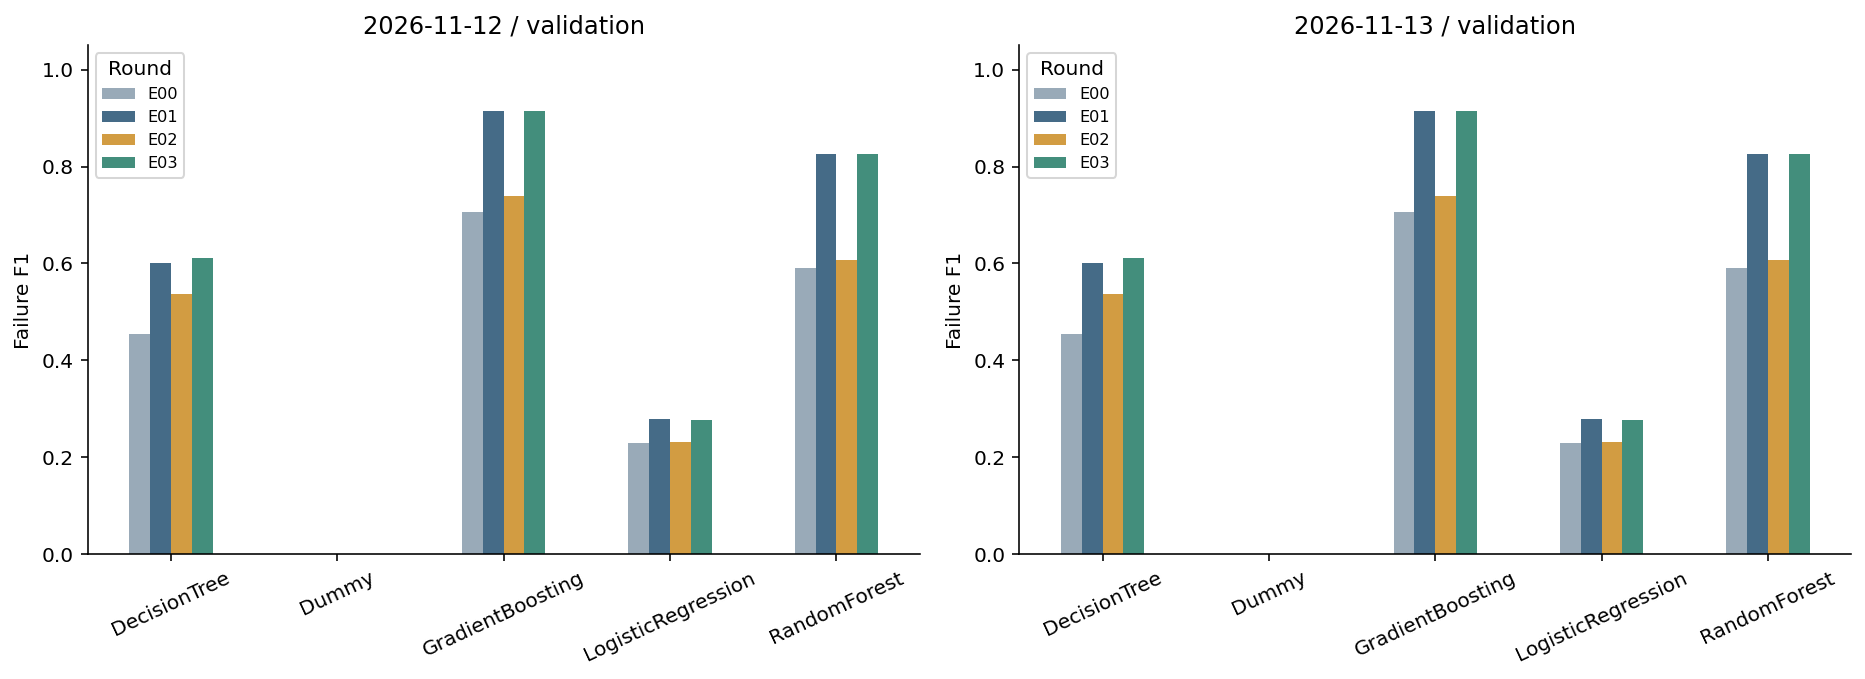

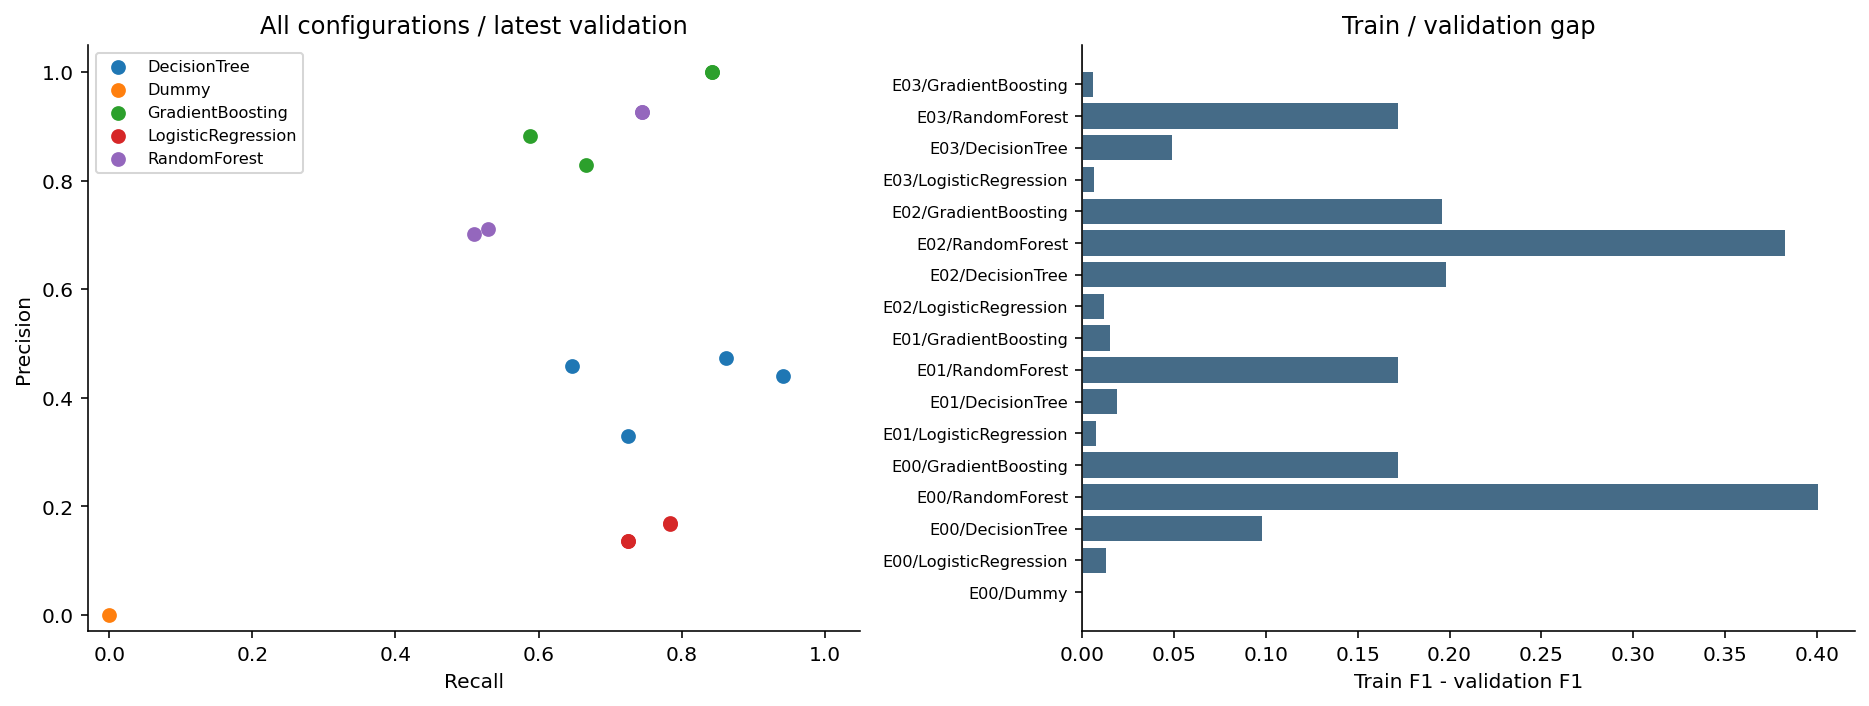

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, name in zip(axes, RUNS):
    part = metrics.loc[metrics.result_set.eq(name)]
    pivot = part.pivot(index="model", columns="run", values="f1").reindex(columns=["E00", "E01", "E02", "E03"])
    pivot.plot.bar(ax=ax, rot=25, color=["#99aab8", "#456b87", "#d29c42", "#438e7c"])
    ax.set(title=name[:10] + " / validation", ylabel="Failure F1", xlabel="", ylim=(0, 1.05))
    ax.legend(title="Round", fontsize=8)
figure(fig)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
latest = metrics.loc[metrics.result_set.eq(RUNS[-1])].copy()
for model, part in latest.groupby("model"):
    axes[0].scatter(part.recall, part.precision, label=model, s=40)
axes[0].set(xlabel="Recall", ylabel="Precision", title="All configurations / latest validation", xlim=(-.03, 1.05), ylim=(-.03, 1.05))
axes[0].legend(fontsize=8)
latest["configuration"] = latest["run"] + "/" + latest["model"]
axes[1].barh(latest.configuration, latest.f1_gap, color="#456b87")
axes[1].axvline(0, color="#aaa", lw=1)
axes[1].set(xlabel="Train F1 - validation F1", title="Train / validation gap")
axes[1].tick_params(axis="y", labelsize=8)
figure(fig)


## 8. Hai lần chạy có tạo thêm bằng chứng độc lập không?

So sánh từng cấu hình, từng row_index, nhãn dự đoán, xác suất và toàn bộ độ đo. Cùng dữ liệu, cùng split và cùng cấu hình là kiểm tra tái lập; ngày chạy khác nhau không tạo ra validation độc lập. Thời gian fit được lưu riêng và không được dùng như thước đo chất lượng dự đoán.

In [9]:
comparison_rows = []
metric_names = ["precision", "recall", "f1", "roc_auc", "average_precision", "accuracy", "tn", "fp", "fn", "tp"]
for _, row in logs[RUNS[0]].iterrows():
    key = (row["run"], row["model"])
    a, b = [predictions[(name, *key)] for name in RUNS]
    ma, mb = [metrics.loc[(metrics.result_set == name) & (metrics.run == key[0]) & (metrics.model == key[1])].iloc[0] for name in RUNS]
    comparison_rows.append({"run": key[0], "model": key[1],
        "changed_predictions": int(a.predicted.ne(b.predicted).sum()),
        "max_probability_difference": float(np.abs(a.failure_probability-b.failure_probability).max()),
        "max_metric_difference": float(max(abs(ma[m]-mb[m]) for m in metric_names)),
        "f1_delta_13_minus_12": float(mb.f1-ma.f1)})
cross_run = pd.DataFrame(comparison_rows)
table(cross_run)
print("Different predicted labels:", int(cross_run.changed_predictions.sum()))
print("Maximum probability difference:", cross_run.max_probability_difference.max())
print("Maximum metric difference:", cross_run.max_metric_difference.max())


run,model,changed_predictions,max_probability_difference,max_metric_difference,f1_delta_13_minus_12
E00,Dummy,0,0.0000,0.0000,0.0000
E00,LogisticRegression,0,0.0000,0.0000,0.0000
E00,DecisionTree,0,0.0000,0.0000,0.0000
E00,RandomForest,0,0.0000,0.0000,0.0000
E00,GradientBoosting,0,0.0000,0.0000,0.0000
E01,LogisticRegression,0,0.0000,0.0000,0.0000
E01,DecisionTree,0,0.0000,0.0000,0.0000
E01,RandomForest,0,0.0000,0.0000,0.0000
E01,GradientBoosting,0,0.0000,0.0000,0.0000
E02,LogisticRegression,0,0.0000,0.0000,0.0000


Different predicted labels: 0
Maximum probability difference: 0.0
Maximum metric difference: 0.0


## 9. Gradient Boosting E01/E03: ma trận nhầm lẫn, PR và các mẫu bỏ sót

Hai cấu hình có F1 cao nhất theo kết quả hiện có. PR dùng xác suất lưu sẵn với đường nền là tỷ lệ lỗi validation. Bảng FN/FP chỉ dùng chẩn đoán kết quả đã có; không tối ưu ngưỡng hoặc chỉnh đặc trưng trên validation trong phân tích này.

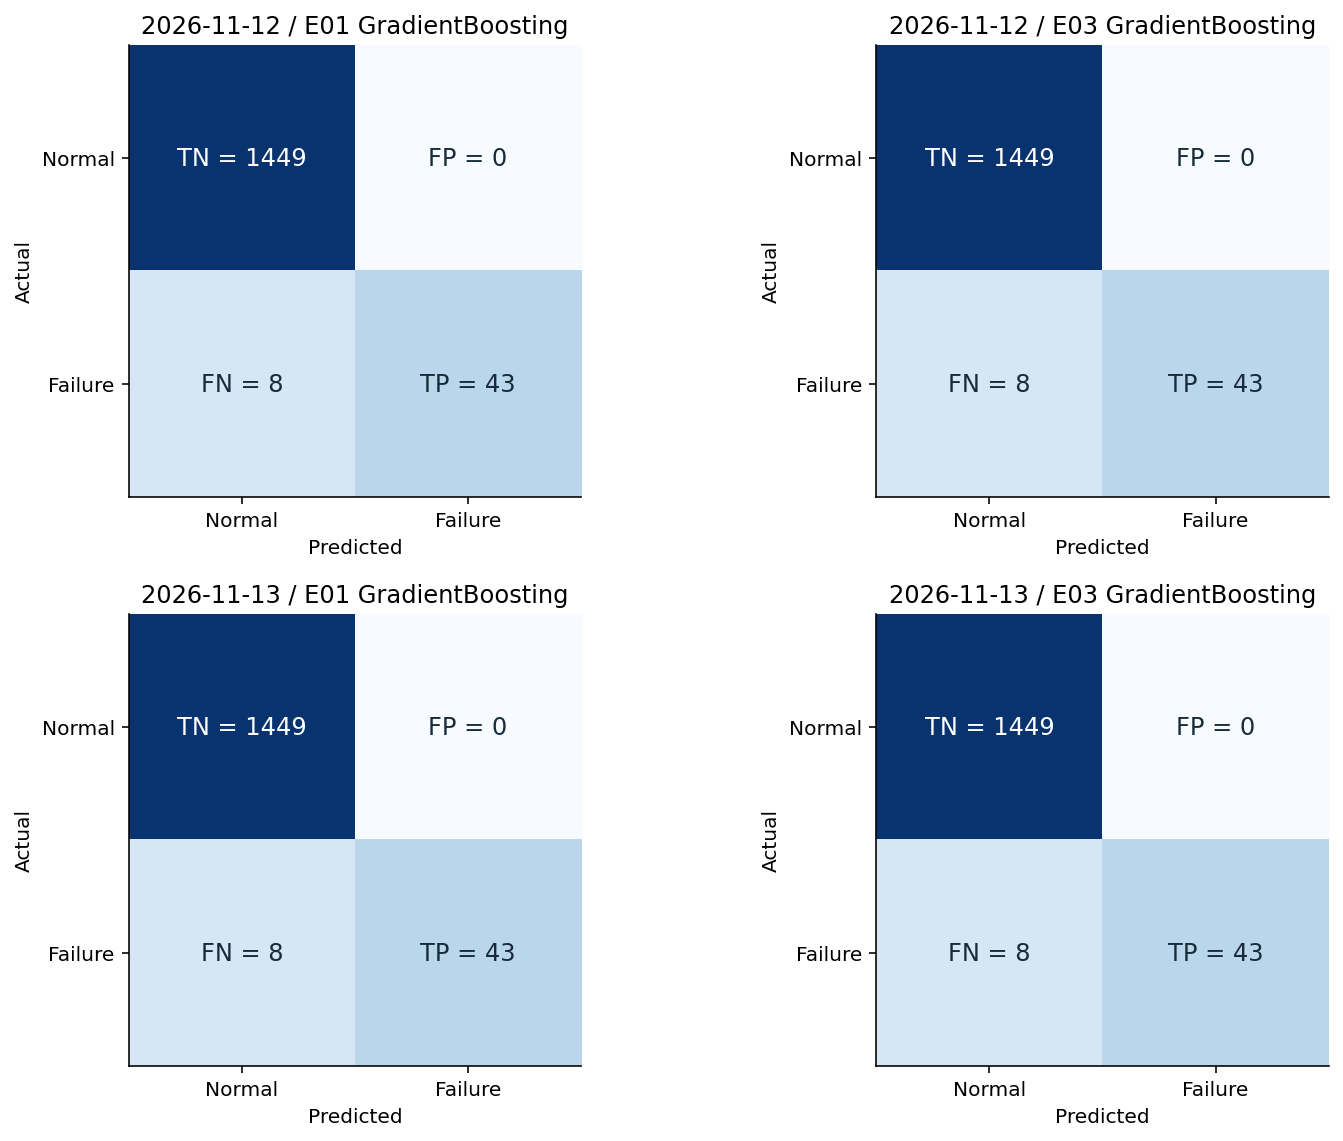

result_set,run,row_index,UDI,actual,predicted,failure_probability,outcome,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF
2026-11-12_194905_617600,E01,2671,2672,1,0,0.0490,FN,M,299.7000,309.3000,1399,41.9000,221,1,0,0,0,0
2026-11-12_194905_617600,E01,3695,3696,1,0,0.0438,FN,L,302.2000,311.3000,1530,37.3000,207,1,0,0,0,0
2026-11-12_194905_617600,E01,3806,3807,1,0,0.3390,FN,M,302.3000,310.9000,1360,44.0000,67,0,1,0,0,0
2026-11-12_194905_617600,E01,4034,4035,1,0,0.0396,FN,L,302.0000,310.8000,1615,29.0000,235,1,0,0,0,0
2026-11-12_194905_617600,E01,7087,7088,1,0,0.0607,FN,L,300.6000,310.3000,1648,30.5000,217,1,0,0,0,0
2026-11-12_194905_617600,E01,7849,7850,1,0,0.0254,FN,M,300.3000,311.7000,1374,47.9000,222,1,0,0,0,0
2026-11-12_194905_617600,E01,8506,8507,1,0,0.0012,FN,L,298.4000,309.6000,1710,27.3000,163,0,0,0,0,0
2026-11-12_194905_617600,E01,9015,9016,1,0,0.0520,FN,L,297.2000,308.1000,1431,49.7000,210,0,0,0,0,0
2026-11-12_194905_617600,E03,2671,2672,1,0,0.0589,FN,M,299.7000,309.3000,1399,41.9000,221,1,0,0,0,0
2026-11-12_194905_617600,E03,3695,3696,1,0,0.0470,FN,L,302.2000,311.3000,1530,37.3000,207,1,0,0,0,0


result_set,run,outcome,observations,TWF,HDF,PWF,OSF,RNF
2026-11-12_194905_617600,E01,FN,8,5,1,0,0,0
2026-11-12_194905_617600,E03,FN,8,5,1,0,0,0
2026-11-13_113519_605332,E01,FN,8,5,1,0,0,0
2026-11-13_113519_605332,E03,FN,8,5,1,0,0,0


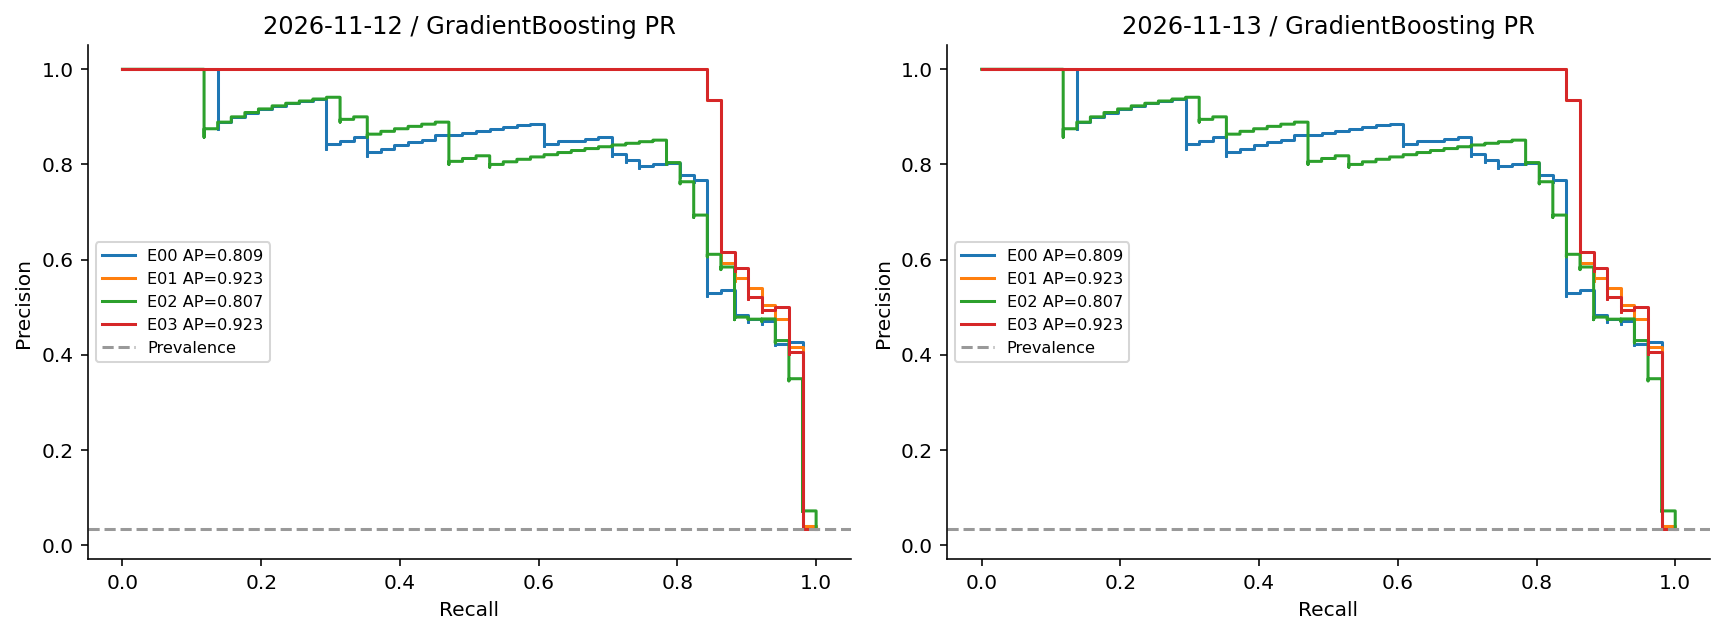

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
errors = []
for i, name in enumerate(RUNS):
    for j, round_name in enumerate(["E01", "E03"]):
        pred = predictions[(name, round_name, "GradientBoosting")]
        cm = confusion_matrix(pred.actual, pred.predicted, labels=[0, 1])
        ax = axes[i, j]
        ax.imshow(cm, cmap="Blues", norm=matplotlib.colors.PowerNorm(gamma=.35, vmin=0, vmax=1500))
        for y in range(2):
            for x in range(2):
                ax.text(x, y, f"{[['TN','FP'],['FN','TP']][y][x]} = {cm[y,x]}",
                    ha="center", va="center", color="white" if cm[y,x] > 500 else "#172b3a", fontsize=12)
        ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["Normal","Failure"],
            yticklabels=["Normal","Failure"], xlabel="Predicted", ylabel="Actual",
            title=f"{name[:10]} / {round_name} GradientBoosting")
        wrong = pred.loc[pred.outcome.isin(["FN", "FP"])].copy()
        wrong = wrong.merge(df[["UDI", "Type", *NUM, *MODES]], on="UDI", validate="one_to_one")
        wrong.insert(0, "result_set", name); wrong.insert(1, "run", round_name)
        errors.append(wrong)
figure(fig)
error_rows = pd.concat(errors, ignore_index=True)
table(error_rows)
error_summary = error_rows.groupby(["result_set", "run", "outcome"]).agg(
    observations=("UDI", "size"), TWF=("TWF", "sum"), HDF=("HDF", "sum"),
    PWF=("PWF", "sum"), OSF=("OSF", "sum"), RNF=("RNF", "sum")).reset_index()
table(error_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, RUNS):
    for round_name in ["E00", "E01", "E02", "E03"]:
        pred = predictions[(name, round_name, "GradientBoosting")]
        precision, recall, _ = precision_recall_curve(pred.actual, pred.failure_probability)
        ap = average_precision_score(pred.actual, pred.failure_probability)
        ax.step(recall, precision, where="post", label=f"{round_name} AP={ap:.3f}")
    ax.axhline(pred.actual.mean(), color="#999", linestyle="--", label="Prevalence")
    ax.set(title=name[:10] + " / GradientBoosting PR", xlabel="Recall", ylabel="Precision", ylim=(-.03,1.05))
    ax.legend(fontsize=8)
figure(fig)


## 10. Nhận xét từ số liệu và giới hạn

Train có 7,000 mẫu và 237 mẫu lỗi (3.39%). Toàn nguồn có 27 quan sát mà nhãn tổng khác OR của các cờ lỗi; giữ nhãn nguồn. Trên train, Type L có tỷ lệ lỗi 4.15%, Type M 2.31%, Type H 1.99%. Nhiệt độ khí và nhiệt độ quá trình tương quan 0.878; tốc độ và mô-men tương quan -0.874. Cấu hình dẫn đầu đồng hạng gồm GradientBoosting E01/E03: F1 validation 0.9149, precision 1.0000, recall 0.8431, TP=43, FN=8, FP=0. Trong 8 FN của từng cấu hình E01/E03 ở cả hai ngày, 5 mẫu có cờ TWF, 1 mẫu có cờ HDF, 2 mẫu không có cờ loại lỗi; đây là các nhóm cần chú ý khi chẩn đoán. Giữa hai ngày, tổng số nhãn dự đoán thay đổi là 0, chênh lệch độ đo lớn nhất 0. Không xem hai lần chạy này là hai lần đánh giá độc lập. Tuning không bảo đảm cải thiện: cần đọc từng cặp E00/E02 và E01/E03 trong bảng. Các quan hệ EDA là mô tả trên dữ liệu mô phỏng; chưa có kết quả test hoặc dữ liệu vận hành bên ngoài. Nếu tiếp tục phát triển mô hình, đặt giả thuyết trên train/CV và chỉ đánh giá test theo giao thức chốt trước.

In [11]:
reproducibility = {
    "analyzed_at": datetime.now(timezone(timedelta(hours=7))).isoformat(timespec="seconds"),
    "github_source_commit": "820f0bd", "data_sha256": data_hash,
    "result_sets": RUNS, "same_split": same_split,
    "python_eda": platform.python_version(),
    "libraries_eda": {"pandas": pd.__version__, "numpy": np.__version__,
        "matplotlib": matplotlib.__version__, "scikit-learn": sklearn.__version__},
    "verified_prediction_files": len(checks), "test_evaluated": False,
    "models_retrained": False, "saved_models_reloaded": False,
    "changed_predicted_labels": int(cross_run.changed_predictions.sum()),
    "max_probability_difference": float(cross_run.max_probability_difference.max()),
    "max_metric_difference": float(cross_run.max_metric_difference.max()),
    "train_row_index_sha256": hashlib.sha256(np.sort(train_ids).astype("<i8").tobytes()).hexdigest(),
}
display(pd.DataFrame([{"item": key, "value": str(value)} for key, value in reproducibility.items()]))
assert len(checks) == 34
assert not plt.get_fignums()
print("Completed EDA; 34 prediction CSVs verified; no test evaluation or model retraining.")


item,value
analyzed_at,2026-11-13T13:40:51+07:00
github_source_commit,820f0bd
data_sha256,dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
result_sets,"['2026-11-12_194905_617600', '2026-11-13_113519_605332']"
same_split,True
python_eda,3.13.2
libraries_eda,"{'pandas': '3.0.2', 'numpy': '2.4.4', 'matplotlib': '3.10.8', 'scikit-learn': '1.8.0'}"
verified_prediction_files,34
test_evaluated,False
models_retrained,False


Completed EDA; 34 prediction CSVs verified; no test evaluation or model retraining.
